In [1]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import catutil as utilities

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd wrkDir/s19/s19-1/

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [3]:
fieldname='WIDE12H'
datFname=os.path.join('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/',\
                      '%s_no_m.fits' %fieldname)
assert os.path.isfile(datFname)
data= pyfits.getdata(datFname)
absE=utilities.get_abs_ellip(data)
logR=np.log10(utilities.get_sdss_size(data))
imag=data['forced_i_cmodel_mag']-data['a_i']
rmag=data['forced_r_cmodel_mag']-data['a_r']
gmag=data['forced_g_cmodel_mag']-data['a_g']

/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/catutil.py:1248: RuntimeWarning: invalid value encountered in power
  size = (gal_mxx * gal_myy - gal_mxy**2)**(0.25)


0.004645386533067526


/work/xiangchong.li/miniconda3/envs/cosmosis-mpich/lib/python3.7/site-packages/ipykernel_launcher.py:25: RuntimeWarning: invalid value encountered in subtract


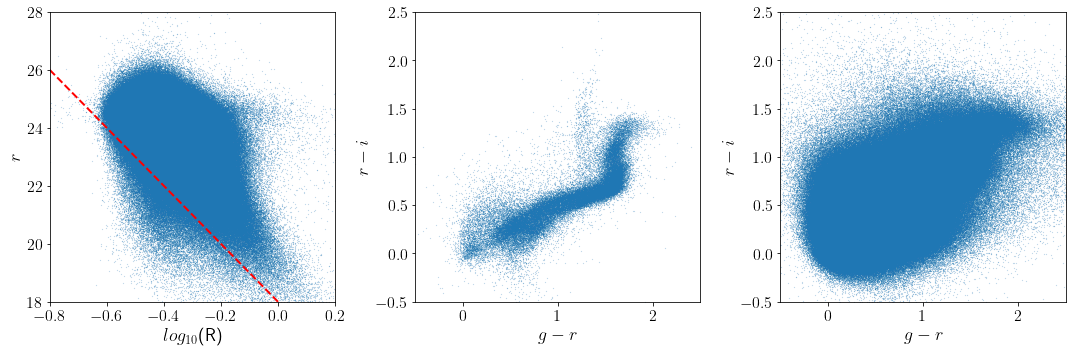

In [5]:
msk=absE>0.8
fig=plt.figure(figsize=(15,5))
fig.add_subplot(1,3,1)
plt.scatter(logR[msk],rmag[msk],s=0.01)
a=1;b=10;c=-18.
msk2=(a*rmag+b*logR+c)<0.
msk2=msk&msk2
print(np.sum(msk2)/len(data))
xx=np.linspace(-0.8,0.2,20)
plt.plot(xx,-(b*xx+c)/a,'--',c='red')
plt.ylim(18,28)
plt.xlim(-.8,0.2)
plt.xlabel(r'$log_{10}$(R)')
plt.ylabel(r'$r$')

fig.add_subplot(1,3,2)
plt.scatter(gmag[msk2]-rmag[msk2],rmag[msk2]-imag[msk2],s=0.01)
plt.ylim(-0.5,2.5)
plt.xlim(-0.5,2.5)
plt.xlabel(r'$g-r$')
plt.ylabel(r'$r-i$')

msk3=msk&~msk2
fig.add_subplot(1,3,3)
plt.scatter(gmag[msk3]-rmag[msk3],rmag[msk3]-imag[msk3],s=0.01)
plt.ylim(-0.5,2.5)
plt.xlim(-0.5,2.5)
plt.xlabel(r'$g-r$')
plt.ylabel(r'$r-i$')
plt.tight_layout()

0.0028020870800293265


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:26: RuntimeWarning: invalid value encountered in subtract


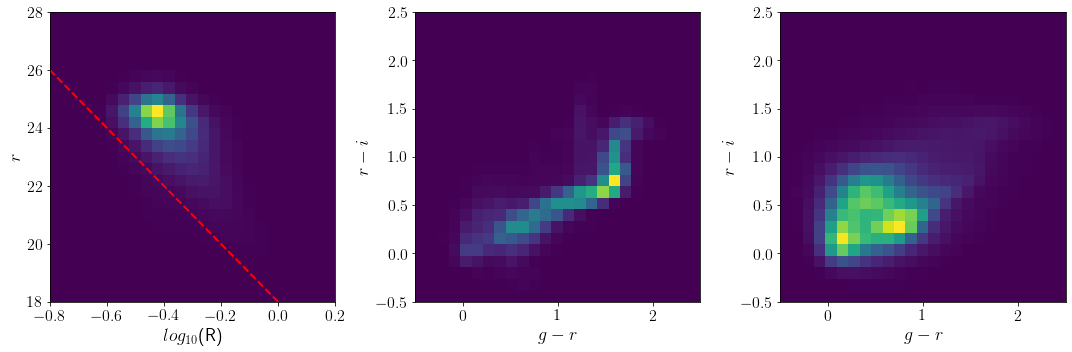

In [183]:
bin=25
msk=absE>0.85
fig=plt.figure(figsize=(15,5))
fig.add_subplot(1,3,1)
plt.hist2d(logR[msk],rmag[msk],range=[(-0.8,0.2),(18,28)],bins=(nbin,nbin),density=True)
a=1;b=10;c=-18.
msk2=(a*rmag+b*logR+c)<0.
msk2=msk&msk2
print(np.sum(msk2)/len(data))
xx=np.linspace(-0.8,0.2,20)
plt.plot(xx,-(b*xx+c)/a,'--',c='red')
plt.ylim(18,28)
plt.xlim(-.8,0.2)
plt.xlabel(r'$log_{10}$(R)')
plt.ylabel(r'$r$')

fig.add_subplot(1,3,2)
plt.hist2d(gmag[msk2]-rmag[msk2],rmag[msk2]-imag[msk2],range=[(-0.5,2.5),(-0.5,2.5)],bins=(nbin,nbin),density=True)
plt.ylim(-0.5,2.5)
plt.xlim(-0.5,2.5)
plt.xlabel(r'$g-r$')
plt.ylabel(r'$r-i$')

msk3=msk&~msk2
fig.add_subplot(1,3,3)
plt.hist2d(gmag[msk3]-rmag[msk3],rmag[msk3]-imag[msk3],range=[(-0.5,2.5),(-0.5,2.5)],bins=(nbin,nbin),density=True)
plt.ylim(-0.5,2.5)
plt.xlim(-0.5,2.5)
plt.xlabel(r'$g-r$')
plt.ylabel(r'$r-i$')
plt.tight_layout()
dd=data[msk2]